# Tree comparison v1

Six chronological development evaluations and a reused 2020–2021 stress period.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
root = Path.cwd()
run = root / 'data/derived/tree_comparison_v1'
tables = root / 'reports/tables/tree_comparison_v1'
receipt = json.loads((run / 'validation.json').read_text())
assert receipt['status'] == 'passed' and receipt['tree_fits'] == 120
selection = json.loads((run / 'selection.json').read_text())
selection

{'protocol_sha256': 'a26e99c7d821930b39d3c718d32160e483a9aca65f51528b6d5dead312c20529',
 'development': {'rf': {'configuration': 'rf_08',
   'macro_log_loss': 0.07382583059108906,
   'macro_brier_score': 0.014545149497124245,
   'annual_log_loss_wins': 3,
   'passes_development_gate': False},
  'lgbm': {'configuration': 'lgbm_12',
   'macro_log_loss': 0.07316581128383946,
   'macro_brier_score': 0.014510708849515734,
   'annual_log_loss_wins': 6,
   'passes_development_gate': True}},
 'thresholds': {'prevalence': 0.01601373191589015,
  'logistic': 0.01147423051096359,
  'rf_08': 0.011994909504656405,
  'lgbm_12': 0.01181934963974565}}

In [2]:
grid = pd.read_csv(tables / 'development_grid.csv')
assert len(grid) == 132
display(grid.groupby('configuration')[['log_loss', 'brier_score']].mean().sort_values('log_loss'))
stress = pd.read_csv(tables / 'stress_metrics.csv')
display(stress[stress.group.eq('all')])

,log_loss,brier_score
configuration,,
lgbm_12,0.073166,0.014511
lgbm_11,0.073179,0.014514
lgbm_09,0.073216,0.014522
lgbm_10,0.073225,0.014522
lgbm_08,0.073280,0.014521
lgbm_07,0.073288,0.014522
lgbm_05,0.073306,0.014527
lgbm_06,0.073315,0.014527
lgbm_04,0.073419,0.014529


,model,period,group,n,fatal,fatal_proportion,mean_prediction,mean_predicted_probability,observed_prevalence,threshold,...,ece,tn,fp,fn,tp,precision,recall,f1,sparse_n_lt_100_or_fatal_lt_5,flagged_fraction
0,prevalence,pooled,all,163580,3230,0.019746,0.016014,0.016014,0.019746,0.016014,...,0.003732,0,160350,0,3230,0.019746,1.000000,0.038727,False,1.000000
1,prevalence,2020,all,79990,1602,0.020028,0.016014,0.016014,0.020028,0.016014,...,0.004014,0,78388,0,1602,0.020028,1.000000,0.039269,False,1.000000
7,prevalence,2021,all,83590,1628,0.019476,0.016014,0.016014,0.019476,0.016014,...,0.003462,0,81962,0,1628,0.019476,1.000000,0.038208,False,1.000000
13,logistic,pooled,all,163580,3230,0.019746,0.016004,0.016004,0.019746,0.011474,...,0.003807,71685,88665,571,2659,0.029116,0.823220,0.056243,False,0.558283
14,logistic,2020,all,79990,1602,0.020028,0.016037,0.016037,0.020028,0.011474,...,0.004029,35096,43292,282,1320,0.029588,0.823970,0.057126,False,0.557720
20,logistic,2021,all,83590,1628,0.019476,0.015972,0.015972,0.019476,0.011474,...,0.003595,36589,45373,289,1339,0.028665,0.822482,0.055399,False,0.558823
26,rf_08,pooled,all,163580,3230,0.019746,0.016014,0.016014,0.019746,0.011995,...,0.003732,73521,86829,597,2633,0.029431,0.815170,0.056812,False,0.546901
27,rf_08,2020,all,79990,1602,0.020028,0.016071,0.016071,0.020028,0.011995,...,0.003956,35645,42743,299,1303,0.029583,0.813358,0.057089,False,0.550644
33,rf_08,2021,all,83590,1628,0.019476,0.015959,0.015959,0.019476,0.011995,...,0.003517,37876,44086,298,1330,0.029285,0.816953,0.056543,False,0.543319
39,lgbm_12,pooled,all,163580,3230,0.019746,0.016061,0.016061,0.019746,0.011819,...,0.003685,75359,84991,586,2644,0.030171,0.818576,0.058196,False,0.535732


feature,C_HOUR,C_MNTH,C_RALN,C_RCFG,C_RSUR,C_TRAF,C_WDAY,C_WTHR
model,,,,,,,,
lgbm_12,0.001610,0.000243,0.001171,0.000826,0.000729,0.003378,0.000234,0.000223
logistic,0.001273,0.000071,0.000918,0.000538,0.000562,0.002254,0.000068,0.000078
rf_08,0.001129,0.000070,0.001241,0.000930,0.000421,0.002600,0.000094,0.000144


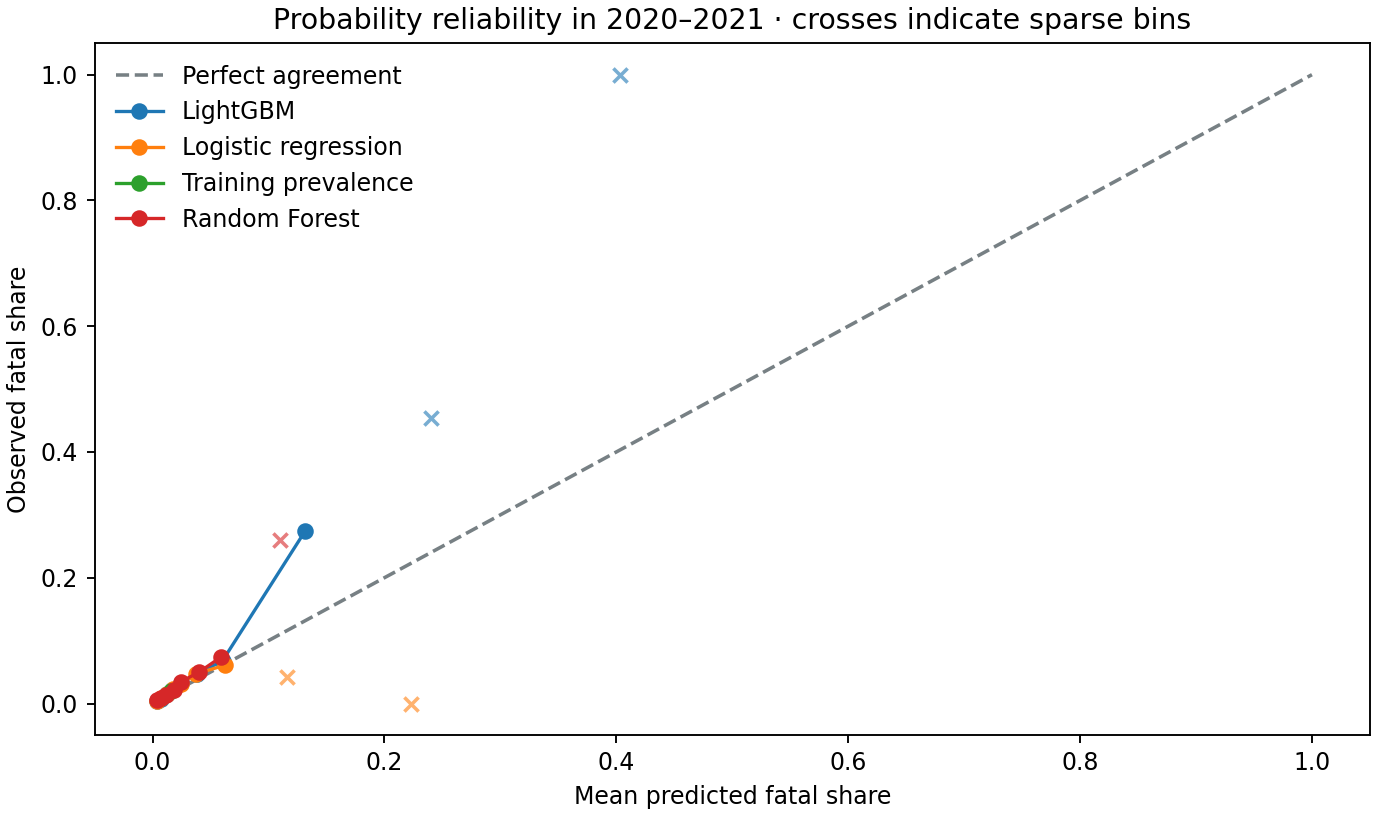

In [3]:
importance = pd.read_csv(tables / 'permutation_importance.csv')
display(importance.groupby(['model','feature']).delta_log_loss.mean().unstack())
display(Image(filename=str(root / 'reports/figures/tree_comparison_reliability.png')))